# **Exercicio Duelo de Modelos 4**

Nesta tarefa, vocês irão criar o seu próprio duelo de modelos, com o objetivo de superar os resultados apresentados em aula. O desafio é alcançar um desempenho superior ao que obtivemos, e para isso, será necessário aplicar todas as melhorias que vocês aprenderam ao longo dos módulos, utilizando a base de dados do Titanic.

**1. Escolha do Modelo:**
Selecione um dos modelos que foram explorados nos duelos de modelos ao longo do curso. Pode ser SVM, Random Forest, XGBoost, ou qualquer outro que tenhamos abordado.

**2. Aperfeiçoamento:**
**Aplique as técnicas que aprendemos para melhorar o desempenho do seu modelo:**

**Hiperparâmetros:** Utilize GridSearchCV ou RandomSearchCV para encontrar os melhores parâmetros.

**Cross Validation:** Avalie a robustez do modelo utilizando validação cruzada para garantir que ele generaliza bem.

**Balanceamento de Classes:** Se o seu modelo lida com problemas de classes desbalanceadas, explore técnicas como SMOTE, undersampling ou oversampling.

**Padronização e Normalização:** Lembre-se de padronizar os dados, especialmente se for usar modelos que são sensíveis à escala das variáveis.

**3. Submissão no Kaggle:**
Treine o seu modelo com os dados de treino e gere as previsões para os dados de teste. Lembre-se de que o conjunto de teste não possui a variável alvo (y_test), pois a avaliação será feita com base nas submissões no Kaggle.
Submeta suas previsões na competição do Titanic no Kaggle.

**4. Entrega:**
Envie o código que você desenvolveu, detalhando cada etapa do seu processo de modelagem, explicando as escolhas feitas e como essas ajudaram a melhorar o modelo.

Junto com o código, envie um print do seu score obtido na plataforma do Kaggle. Esse score será a sua métrica final de avaliação, mostrando como o seu modelo se compara com os demais.

**5. Competição Saudável:**
A ideia é trazer um senso de competição saudável, então não vale replicar exatamente o que fizemos na aula! Inove, explore novas combinações de parâmetros e técnicas, e mostre do que é capaz. O importante é exercitar o pensamento crítico e a capacidade de experimentar.

**Dicas Finais:**

Seja criativo e tenha um olhar crítico sobre o que pode ser melhorado.
Teste diferentes abordagens e não se prenda a um único caminho.
Lembre-se de que, mais do que alcançar o melhor score, o objetivo é aprender e aplicar o conhecimento de forma prática e eficaz.
Boa sorte! Estamos ansiosos para ver como cada um de vocês vai se sair nesse desafio e quais insights irão surgir dessa competição!

Ao final dessa atividade vocês terão participado da primeira competição publica de ciência de dados de vocês = )




---
# Minha solução

Neste notebook eu conto o caminho que percorri para resolver o duelo: o que eu fiz, **por que** fiz e o que aprendi em cada etapa.

Decidi não concentrar todo o código aqui. Organizei a solução como um pacote Python testado (`src/titanic/`, 65 testes automatizados), versionado no GitHub com um commit por etapa. Este notebook importa esse pacote e foca na narrativa e nas decisões.

📦 Repositório: [github.com/RToyoyama/titanic-duelo-final](https://github.com/RToyoyama/titanic-duelo-final)

### Meu resultado em uma tabela

| Modelo | Acurácia CV (5×3) | Kaggle |
|---|---|---|
| Referência: "só mulheres sobrevivem" | — | ~0.766 |
| Meu baseline (regressão logística, parâmetros padrão) | 0.8373 | — |
| Random Forest tunado | 0.8485 | 0.77751 |
| **Votação hard — modelo final** | **0.8503** | **0.77751** |

### Como organizei o trabalho

1. EDA orientada a decisões
2. Feature engineering sem vazamento de alvo
3. Pré-processamento em pipeline (padronização incluída)
4. Duelo baseline com validação cruzada repetida
5. Experimento de balanceamento de classes
6. Tuning de hiperparâmetros
7. Ensembles (votação e stacking)
8. Um experimento extra que não deu certo (e por quê)
9. Submissão no Kaggle
10. Conclusões e aprendizados

## Setup

In [1]:
import inspect
import json
from collections.abc import Callable

import pandas as pd
from IPython.display import Image, display

from titanic import balancing, ensemble, evaluate, tuning, wcg
from titanic.config import BEST_PARAMS_PATH, FIGURES_DIR, REPORTS_DIR, SUBMISSIONS_DIR, TARGET
from titanic.data import load_raw
from titanic.features import build_train_test
from titanic.predict import validate_submission
from titanic.preprocessing import build_preprocessor
from titanic.transformers import GroupSurvivalEncoder

pd.set_option("display.max_columns", 30)

# False: lê os resultados salvos em reports/ (rápido).
# True: refaz todos os experimentos do zero (~20 minutos).
RERUN_EXPERIMENTS = False


def show_figure(name: str) -> None:
    """Exibe uma figura salva em reports/figures."""
    display(Image(filename=str(FIGURES_DIR / f"{name}.png")))


def load_results(name: str, runner: Callable[[], None], **read_kwargs) -> pd.DataFrame:
    """Lê um resultado salvo; se RERUN_EXPERIMENTS, executa o experimento antes."""
    if RERUN_EXPERIMENTS:
        runner()
    return pd.read_csv(REPORTS_DIR / f"{name}.csv", **read_kwargs)

## 1. O que os dados me mostraram (EDA)

A análise completa está em `notebooks/01_eda.ipynb`. Aqui eu trago só o que mudou as minhas decisões.

- **Sexo e classe dominam.** Mulheres sobreviveram ~74% contra ~19% dos homens; a 1ª classe ~63% contra ~24% da 3ª.
- **O nome guarda informação.** Extraí o título (`Mr`, `Mrs`, `Miss`, `Master`) e percebi que ele resume sexo, idade e status numa variável só. Meninos (`Master`) sobrevivem 3,5× mais que homens adultos (`Mr`).
- **A sobrevivência não é individual.** Quando outros membros do mesmo ticket sobreviveram, a chance individual sobe para ~70%+. Foi o sinal mais forte que encontrei além de sexo e classe.
- **Faltar um dado também é informação.** Não ter cabine registrada (~77% dos passageiros) já indica menor chance de sobreviver.
- **A tarifa engana.** `Fare` é o preço do ticket inteiro, não por pessoa. Criei `FarePerPerson` para corrigir essa distorção.
- **O desbalanceamento é leve (62/38).** Anotei a hipótese de que balancear traria pouco ganho, e testei isso na etapa 5.

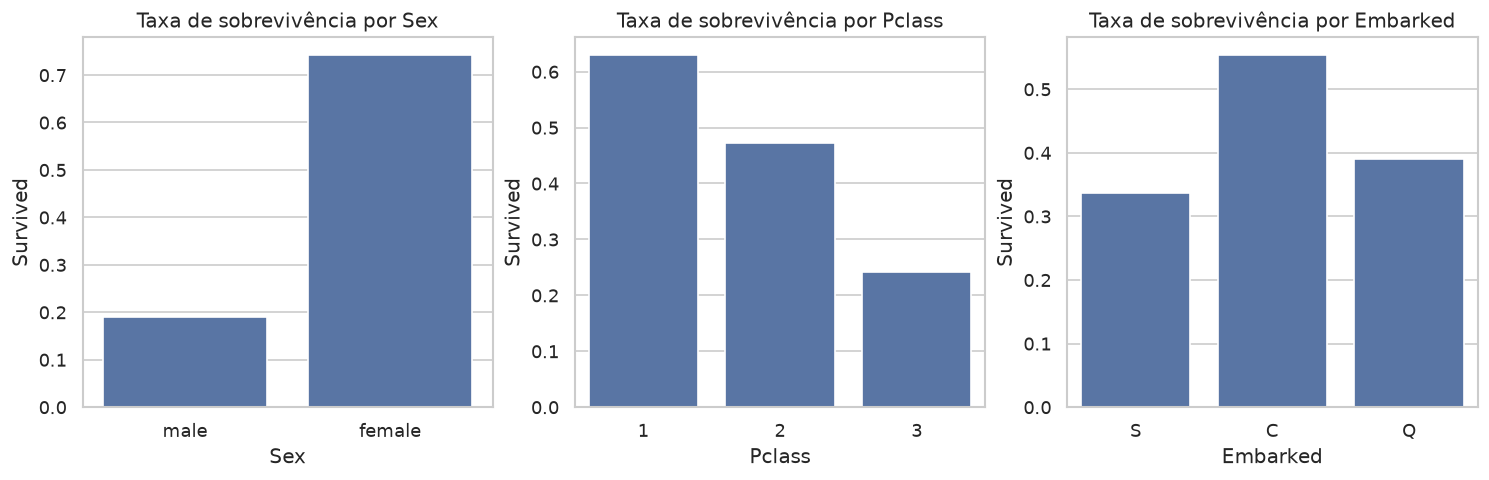

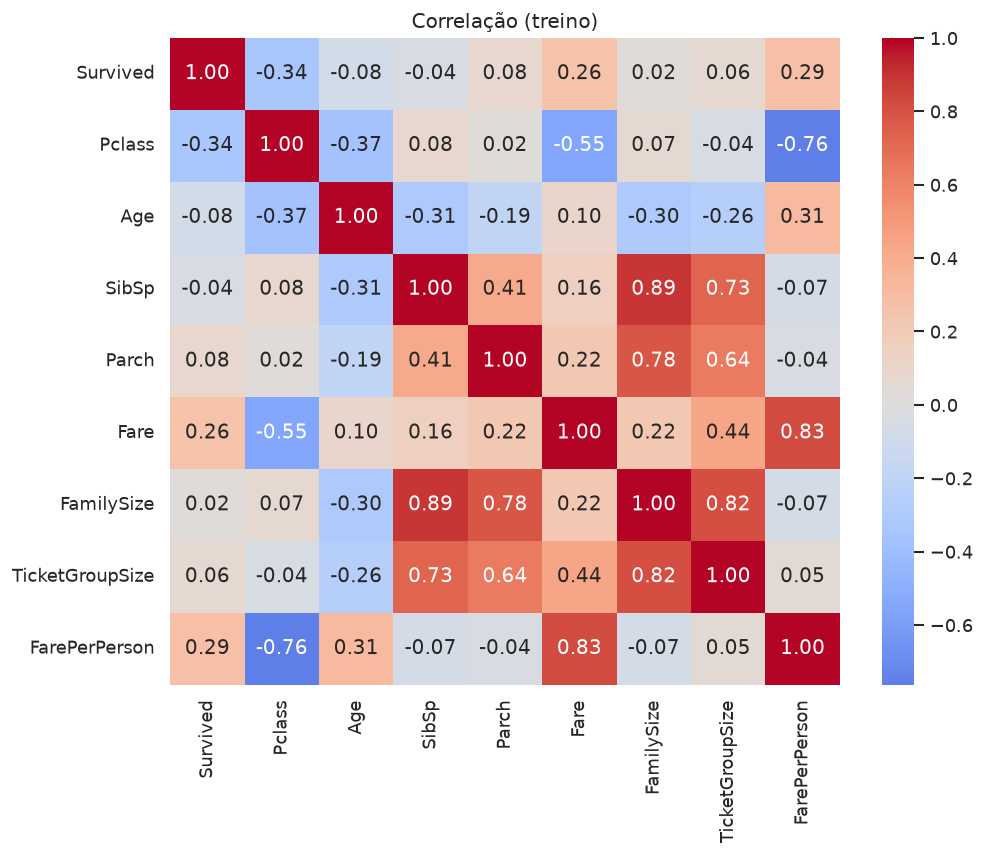

In [2]:
show_figure("survival_by_category")
show_figure("correlation_heatmap")

No heatmap, reparei que `FamilySize` tem correlação quase zero com o alvo. Mesmo assim, eu **não** descartei a variável: na EDA a relação dela com a sobrevivência tem formato de U (sozinho e família grande sobrevivem menos que famílias de 2 a 4 pessoas). Correlação de Pearson só mede relação linear.

## 2. Feature engineering

Separei as features em dois tipos. Essa separação foi a decisão de engenharia mais importante do projeto:

| Tipo | Exemplos | Onde calculo | Por quê |
|---|---|---|---|
| Não usam o alvo | Title, FamilySize, FamilyBand, Deck, HasCabin, TicketGroupSize, FarePerPerson | `features.py`, antes da CV | Não há como vazar informação |
| Aprendem dos dados | Age imputada pela mediana do Title, sobrevivência do grupo | `transformers.py`, **dentro** de cada fold | Calculadas antes da CV, deixariam os folds de validação "verem" o próprio resultado |

In [3]:
train, test = build_train_test(*load_raw())
X, y = train.drop(columns=TARGET), train[TARGET]

new_cols = ["Title", "FamilySize", "FamilyBand", "Deck", "TicketGroupSize", "FarePerPerson"]
train[["Name", *new_cols, TARGET]].head()

,Name,Title,FamilySize,FamilyBand,Deck,TicketGroupSize,FarePerPerson,Survived
0,"Braund, Mr. Owen Harris",Mr,2,Small,U,1,7.25000,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,Small,ABC,2,35.64165,1
2,"Heikkinen, Miss. Laina",Miss,1,Alone,U,1,7.92500,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,Small,ABC,2,26.55000,1
4,"Allen, Mr. William Henry",Mr,1,Alone,U,1,8.05000,0


### A feature de que mais me orgulho: sobrevivência do grupo sem vazamento

Essa feature usa o **alvo de outros passageiros**, então ela é perigosa. Se eu calculasse a taxa de sobrevivência de cada grupo com o treino inteiro, a validação cruzada mostraria um score inflado que nunca se repetiria no Kaggle.

Minha solução foi um transformer do scikit-learn com duas lógicas:
- **No treino (`fit_transform`)**, uso leave-one-out: o rótulo do próprio passageiro nunca entra no cálculo da feature dele.
- **Na validação e no teste (`transform`)**, uso o grupo inteiro aprendido no treino.

Escrevi um teste que troca o rótulo de um passageiro e confirma que a feature dele não muda. Na CV, essa feature sozinha levou a regressão logística de 0.8294 para 0.8440.

In [4]:
print(inspect.getsource(GroupSurvivalEncoder.fit_transform))

    def fit_transform(self, X: pd.DataFrame, y: ArrayLike | None = None) -> np.ndarray:
        """Ajusta e transforma o treino com leave-one-out.

        Args:
            X: DataFrame com uma única coluna de chave de grupo.
            y: Alvo binário (obrigatório).

        Returns:
            Array (n, 1) com a taxa de sobrevivência dos outros membros.

        Raises:
            ValueError: Se `y` não for informado.
        """
        if y is None:
            raise ValueError("GroupSurvivalEncoder requer y no fit_transform.")
        self.fit(X, y)
        keys = self._keys(X)
        others_sum = keys.map(self.sum_) - np.asarray(y, dtype=float)
        others_count = keys.map(self.count_) - 1
        return self._finalize(others_sum / others_count.replace(0, np.nan))



## 3. Pré-processamento e padronização

Montei um `ColumnTransformer` com um tratamento para cada tipo de coluna:

| Colunas | Tratamento |
|---|---|
| Numéricas | imputação pela mediana + `StandardScaler` |
| Tarifa por pessoa | imputação + `log1p` (a distribuição é muito assimétrica) + `StandardScaler` |
| Idade | imputação pela mediana do Title + `StandardScaler` |
| Categóricas | imputação pela moda + one-hot |
| Ticket | sobrevivência do grupo (o transformer acima) |

**Sobre a padronização:** SVM e regressão logística dependem da escala das variáveis, então nelas eu padronizo. Árvores (Random Forest e XGBoost) são indiferentes à escala, então nelas eu desligo o scaler com um parâmetro.

Coloquei tudo **dentro** do pipeline do modelo. Assim, em cada fold da CV, as medianas e as médias do scaler são aprendidas só com os dados de treino daquele fold.

In [5]:
X_prep = build_preprocessor().fit_transform(X, y)
print(f"{X_prep.shape[1]} features | valores faltantes: {int(X_prep.isna().sum().sum())}")
X_prep.head()

26 features | valores faltantes: 0


,Pclass,SibSp,Parch,FamilySize,TicketGroupSize,HasCabin,FarePerPerson,Age,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,FamilyBand_Alone,FamilyBand_Large,FamilyBand_Small,Deck_ABC,Deck_DE,Deck_FG,Deck_U,group_survival
0,0.827377,0.432793,-0.473674,0.059160,-0.624404,-0.544925,-0.548075,-0.557460,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.5
1,-1.566107,0.432793,-0.473674,0.059160,-0.067503,1.835115,1.605745,0.649091,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.5
2,0.827377,-0.474545,-0.473674,-0.560975,-0.624404,-0.544925,-0.434470,-0.255822,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.5
3,-1.566107,0.432793,-0.473674,0.059160,-0.067503,1.835115,1.193777,0.422862,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,0.827377,-0.474545,-0.473674,-0.560975,-0.624404,-0.544925,-0.414378,0.422862,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.5


## 4. Duelo baseline

Coloquei quatro modelos de famílias diferentes para duelar com parâmetros padrão: regressão logística, SVM, Random Forest e XGBoost.

**Minha estratégia de validação:** `RepeatedStratifiedKFold` com 5 folds × 3 repetições (15 avaliações por modelo). Com só 891 linhas, percebi que uma única divisão em 5 folds variava demais: a mesma regressão logística marcou 0.8440 numa divisão e 0.8373 na média das 15.

Além da média, eu comparo os modelos **fold a fold** (comparação pareada), porque todos são avaliados exatamente nos mesmos folds.

In [6]:
baseline = load_results("baseline_results", evaluate.main, index_col=0)
baseline

,acc_mean,acc_std,roc_auc,f1,train_acc,fit_time_s,overfit_gap
model,,,,,,,
xgboost,0.8391,0.0214,0.8821,0.7828,0.9384,0.8225,0.0992
logreg,0.8373,0.0153,0.8894,0.7822,0.9122,0.0638,0.0749
svm,0.8286,0.0227,0.8809,0.7685,0.8533,0.0435,0.0246
random_forest,0.8272,0.0167,0.8808,0.7720,0.9603,0.4546,0.1332


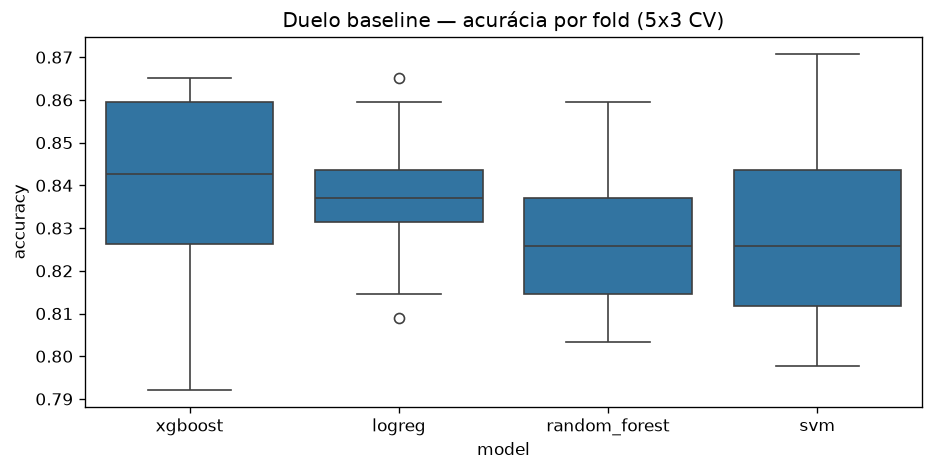

In [7]:
show_figure("baseline_duel")

**O que eu concluí:**

- Deu **empate técnico**. O XGBoost ficou na frente por só 0,19 p.p. e venceu a regressão logística em apenas 40% dos folds. Se eu olhasse só a média, teria declarado um campeão que não existe.
- O Random Forest com parâmetros padrão tinha o maior gap entre treino e validação. As árvores cresciam sem limite e decoravam os dados. Anotei isso como alvo para o tuning.
- **Uma descoberta que eu não esperava:** o `train_acc` está inflado em todos os modelos. Quando o scikit-learn calcula o score de treino, ele chama `transform` no próprio treino, e aí a feature de grupo inclui o rótulo do passageiro. Os scores de **validação** continuam honestos, mas aprendi a não confiar no gap de overfitting como medida absoluta neste projeto.

## 5. Balanceamento de classes

Testei três estratégias nos quatro modelos:

- **Nenhuma:** treina com a proporção real (62/38).
- **`class_weight="balanced"`:** erros na classe minoritária pesam mais (no XGBoost, o equivalente é `scale_pos_weight`).
- **SMOTE:** cria sobreviventes sintéticos. Usei o `Pipeline` do imbalanced-learn, que aplica o SMOTE **só no fit, dentro de cada fold**. Se eu aplicasse no dataset inteiro antes da CV, pontos sintéticos criados a partir da validação vazariam para o treino.

Defini o critério antes de rodar: como o Kaggle avalia por acurácia, eu só adotaria uma estratégia que melhorasse a acurácia.

In [8]:
balance = load_results("balance_results", balancing.main, index_col=["model", "balance"])
balance["acc_mean"].unstack()

balance,class_weight,none,smote
model,,,
logreg,0.8208,0.8373,0.8242
random_forest,0.8197,0.8272,0.8275
svm,0.8238,0.8286,0.8241
xgboost,0.8331,0.8391,0.8279


**O que eu concluí:** não balancear venceu em 3 dos 4 modelos, e no Random Forest a diferença foi de 0,03 p.p. (ruído). Entendi o motivo: as duas técnicas fazem o modelo prever "sobreviveu" com mais frequência, deslocando o limiar de decisão. Isso ajuda quando errar a classe rara custa caro (fraude, diagnóstico), mas a acurácia pesa os dois erros igualmente.

Também me surpreendeu que nem o F1 melhorou de forma consistente. Concluí que o desbalanceamento não era um gargalo deste problema e segui **sem balanceamento**. Mantive o código como experimento documentado: testar e descartar com evidência também é resultado.

## 6. Tuning de hiperparâmetros

Escolhi o tipo de busca conforme o espaço de cada modelo:

| Busca | Modelos | Por quê |
|---|---|---|
| `GridSearchCV` | regressão logística (7 combinações), SVM (16) | Espaço pequeno: dá para testar tudo |
| `RandomizedSearchCV` | Random Forest, XGBoost (40 sorteios cada) | Muitos parâmetros, alguns contínuos |

**Um cuidado que fiz questão de tomar:** o melhor score de uma busca é otimista, porque entre 40 combinações alguma sempre "dá sorte" naqueles folds. Por isso, rodei a busca com **uma seed de CV** e reavaliei os vencedores com **outra seed**. A diferença entre os dois scores mede esse otimismo.

In [9]:
tuning_results = load_results("tuning_results", tuning.main, index_col=0)
tuning_results

,search_score,baseline,tuned,tuned_std,win_rate,gain
random_forest,0.8490,0.8272,0.8485,0.0183,0.9333,0.0213
xgboost,0.8479,0.8391,0.8402,0.0158,0.2667,0.0011
svm,0.8345,0.8286,0.8328,0.0216,0.4667,0.0041
logreg,0.8345,0.8373,0.8324,0.0145,0.1333,-0.0049


In [10]:
print(json.dumps(json.loads(BEST_PARAMS_PATH.read_text()), indent=2))

{
  "logreg": {
    "model__C": 0.3
  },
  "svm": {
    "model__C": 3.0,
    "model__gamma": 0.03
  },
  "random_forest": {
    "model__max_depth": 8,
    "model__max_features": 0.7,
    "model__min_samples_leaf": 4,
    "model__n_estimators": 724
  },
  "xgboost": {
    "model__colsample_bytree": 0.8776807051588262,
    "model__learning_rate": 0.03573884768117847,
    "model__max_depth": 3,
    "model__min_child_weight": 2,
    "model__n_estimators": 359,
    "model__reg_lambda": 0.23426581058204046,
    "model__subsample": 0.9878338511058234
  }
}


**O que eu concluí:**

- O **Random Forest** foi o grande beneficiado: +2,13 p.p., vencendo em 93% dos folds. O tuning limitou a profundidade das árvores (`max_depth=8`, `min_samples_leaf=4`) e confirmou o diagnóstico de overfitting da etapa 4.
- Nos outros três modelos o ganho ficou dentro do ruído.
- No XGBoost, a busca prometia 0.8479 e a reavaliação entregou 0.8402. Sem a seed separada, eu teria superestimado o modelo em 0,77 p.p.
- A regressão logística piorou levemente na reavaliação. Mesmo assim, mantive os parâmetros da busca: se eu escolhesse pelos folds de avaliação, eles deixariam de ser uma avaliação independente. Minha regra foi **a busca escolhe, a avaliação só mede**.

## 7. Ensembles

Antes de combinar os modelos, quis saber se valia a pena. Um ensemble só ajuda se os modelos **erram em passageiros diferentes**. Medi isso com previsões out-of-fold:

| Par de modelos | Correlação dos erros |
|---|---|
| Regressão logística × SVM | 0.82 |
| Random Forest × XGBoost | 0.82 |
| Pares entre as duas famílias | 0.67 a 0.71 |

Os modelos formam duas famílias, e a diversidade está **entre** elas. Por isso mantive os modelos lineares no ensemble, mesmo sendo individualmente mais fracos.

Dois números me ajudaram a calibrar a expectativa:
- **Oráculo de 0.8979:** se eu soubesse escolher o modelo certo para cada passageiro, chegaria a ~90%. É o teto de qualquer combinação.
- **91 passageiros (10%) que todos os modelos erram.** São exceções às regras dos dados, e explicam por que ninguém passa muito de 85% neste problema.

Testei votação hard, votação soft e stacking contra o Random Forest tunado. Para a votação soft e o stacking, troquei o `SVC(probability=True)` por `CalibratedClassifierCV`, porque o parâmetro foi depreciado no scikit-learn 1.9.

In [11]:
ensemble_results = load_results("ensemble_results", ensemble.main, index_col=0)
ensemble_results[["acc_mean", "acc_std", "roc_auc", "f1"]]

,acc_mean,acc_std,roc_auc,f1
model,,,,
voting_hard,0.8503,0.0156,NaN,0.7891
random_forest,0.8485,0.0183,0.8894,0.7889
stacking,0.8444,0.0188,0.8930,0.7880
voting_soft,0.8440,0.0167,0.8940,0.7862


**O que eu concluí:**

- A **votação hard** venceu: 0.8503, com o menor desvio entre os folds, e venceu o Random Forest em 67% deles. Escolhi ela como modelo final.
- **O paradoxo que mais me ensinou:** a votação soft e o stacking tiveram o **melhor ROC AUC** e a **pior acurácia**. O AUC mede se o modelo ordena bem os passageiros; a acurácia depende do limiar de 0.5. Quando as probabilidades são combinadas, elas são puxadas para o meio, e passageiros perto da fronteira caem do lado errado. Na votação hard, cada modelo decide antes, e a decisão confiante de cada um é preservada.
- O stacking, que seria o método mais sofisticado, não compensou. Com 891 linhas, o meta-modelo tem poucos dados para aprender pesos confiáveis. Mais complexo não significou melhor.

## 8. Um experimento extra que não deu certo

Depois da primeira submissão, tentei a técnica **woman-child-group (WCG)**: uma regra aplicada sobre as previsões do modelo, baseada no destino conjunto de mulheres e crianças de uma mesma família.
- Menino de uma família em que todas as mulheres e crianças sobreviveram → previsão vira "sobreviveu".
- Mulher de uma família em que todas as mulheres e crianças morreram → previsão vira "não sobreviveu".

Antes de ver os números, defini que só submeteria se a regra vencesse o modelo base em mais de 60% dos folds.

In [12]:
wcg_results = load_results("wcg_results", wcg.main, index_col=0)
wcg_results[["acc_mean", "acc_std", "f1"]]

,acc_mean,acc_std,f1
model,,,
voting_hard+wcg,0.8522,0.0164,0.7915
voting_hard+wcg_ticket,0.8511,0.0172,0.7900
voting_hard,0.8503,0.0156,0.7891
random_forest+wcg,0.8496,0.0185,0.7902
random_forest,0.8485,0.0183,0.7889
random_forest+wcg_ticket,0.8485,0.0185,0.7887


**O que eu concluí:** a regra trouxe ganhos de 0 a 0,19 p.p., com win rate entre 7% e 33%, e mudaria no máximo **1 previsão** no conjunto de teste. Não passou no critério, e eu não submeti.

O motivo foi, na verdade, uma boa notícia: o modelo **já tinha aprendido** esse padrão. A feature de sobrevivência do grupo, junto com `Title` e `Sex`, já levava o modelo a prever exatamente o que a regra prevê. Definir o critério de decisão antes de ver o resultado me impediu de gastar submissões perseguindo oscilações de um passageiro.

## 9. Submissão no Kaggle

Treinei os modelos finais com as 891 linhas do treino. A CV serviu para **escolher** a configuração; o modelo final aprende com todos os dados.

Antes de submeter, meu código valida o arquivo (418 linhas, colunas corretas, IDs iguais aos do teste, valores só 0 ou 1) e faz checagens de sanidade. Submeti pelo terminal com `make submit`, e cada submissão leva o hash do commit na mensagem. Assim, cada score do leaderboard aponta para a versão exata do código que o gerou.

In [13]:
submission = pd.read_csv(SUBMISSIONS_DIR / "voting_hard.csv")
validate_submission(submission, test)
rate, train_rate = submission[TARGET].mean(), y.mean()
print(f"{len(submission)} linhas | sobrevivência prevista: {rate:.3f} (treino: {train_rate:.3f})")
submission.head()

418 linhas | sobrevivência prevista: 0.361 (treino: 0.384)


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


### Meu score

![Meu score no Kaggle](../reports/figures/kaggle_score.png)

| Submissão | Score público |
|---|---|
| `voting_hard @ 922ed3d` (modelo final) | **0.77751** |
| `random_forest @ 922ed3d` (controle) | 0.77751 |

Os dois modelos discordavam em 18 passageiros e tiveram o mesmo score. Isso significa que cada um acertou exatamente 9 desses 18: no teste, a diferença entre eles foi puro ruído. Na prática, o modelo acerta cerca de 5 passageiros a mais que a regra "só mulheres sobrevivem".

## 10. Conclusões e aprendizados

**O que funcionou**
- A feature de sobrevivência do grupo, implementada sem vazamento: foi o maior ganho isolado do projeto.
- O tuning do Random Forest, que atacou o overfitting diagnosticado no baseline.
- A votação hard entre famílias de modelos diferentes.

**O que não funcionou (e documentei)**
- Balanceamento de classes: com 62/38, ele prejudica a acurácia.
- Stacking e votação soft: melhores em AUC, piores em acurácia.
- A regra WCG: redundante com as features que eu já tinha.

**O que mais me marcou: a distância entre a CV e o Kaggle.** Minha CV indicava 0.85 e o Kaggle deu 0.78. Mesmo tomando cuidado com vazamento, seeds separadas e comparação pareada, cada escolha que eu fiz olhando para a mesma CV acumulou um pouco de otimismo, e o conjunto de teste tem só 418 passageiros. Aprendi a ler a validação cruzada como uma estimativa, e não como uma promessa.

**Lições que levo para outros projetos**
1. Toda estatística aprendida dos dados vai **dentro** do pipeline.
2. Diferença na média não é diferença real: compare fold a fold.
3. Defina o critério de decisão **antes** de ver o resultado.
4. O melhor modelo depende da métrica (AUC × acurácia).
5. Resultado negativo também é resultado.

**Próximos passos que eu exploraria**
- Ampliar o espaço de busca do Random Forest: `max_depth` e `max_features` ficaram na borda do espaço.
- Ajustar o limiar de decisão da votação soft, que tem o melhor AUC.
- Testar `SMOTENC`, que trata colunas categóricas corretamente.

## Como reproduzir

```bash
git clone https://github.com/RToyoyama/titanic-duelo-final.git
cd titanic-duelo-final
uv venv --python 3.11 --seed .venv && source .venv/bin/activate
make install    # dependências + hooks de pre-commit
make data       # baixa os dados (requer token do Kaggle)
make test       # 65 testes
make baseline   # etapa 4
make balance    # etapa 5
make tune       # etapa 6 (~10 min)
make ensemble   # etapa 7
make wcg        # etapa 8
make predict    # gera as submissões
make submit     # envia ao Kaggle
```